# Task 3: Predictive Customer Churn Classifier

In this notebook, I am building an ensemble machine learning pipeline to predict customer churn using telecom subscription records.
Since customer churn datasets usually suffer from class imbalance, I am using SMOTE (or class weights) along with Random Forest and XGBoost classifiers to optimize ROC-AUC score above 80%.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

## 1. Data Loading & Synthetic Dataset Setup
Loading the Telco Customer Churn dataset structure. Handling data types like TotalCharges and null values.

In [7]:
#  load Telco Churn structured dataset for demonstration
np.random.seed(42)
n_samples = 1500

data = {
    'gender': np.random.choice(['Male', 'Female'], n_samples),
    'SeniorCitizen': np.random.choice([0, 1], n_samples, p=[0.85, 0.15]),
    'Partner': np.random.choice(['Yes', 'No'], n_samples),
    'Dependents': np.random.choice(['Yes', 'No'], n_samples),
    'tenure': np.random.randint(1, 72, n_samples),
    'PhoneService': np.random.choice(['Yes', 'No'], n_samples),
    'Contract': np.random.choice(['Month-to-month', 'One year', 'Two year'], n_samples, p=[0.55, 0.25, 0.20]),
    'PaperlessBilling': np.random.choice(['Yes', 'No'], n_samples),
    'PaymentMethod': np.random.choice(['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card'], n_samples),
    'MonthlyCharges': np.random.uniform(18.25, 118.75, n_samples),
    'TotalCharges': np.random.uniform(18.25, 8000.0, n_samples),
    'Churn': np.random.choice(['Yes', 'No'], n_samples, p=[0.27, 0.73]) # Class Imbalance
}

df = pd.DataFrame(data)

# Handling TotalCharges numeric conversion
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Encode Target Variable
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Dataset Shape:", df.shape)
print("Class Imbalance Ratio:")
print(df['Churn'].value_counts(normalize=True))
df.head()

Dataset Shape: (1500, 12)
Class Imbalance Ratio:
Churn
0    0.736667
1    0.263333
Name: proportion, dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,Yes,Yes,12,Yes,Month-to-month,Yes,Credit card,117.970312,82.358329,0
1,Female,1,Yes,Yes,4,Yes,One year,Yes,Mailed check,83.837647,3945.923152,0
2,Male,0,Yes,Yes,48,Yes,Two year,No,Bank transfer,24.410529,4259.439318,0
3,Male,0,Yes,No,55,No,Two year,Yes,Electronic check,71.070727,1624.580097,0
4,Male,0,No,Yes,1,No,Month-to-month,Yes,Credit card,68.162844,2290.449828,0


## 2. Preprocessing & Handling Imbalance using SMOTE
Setting up OneHotEncoder for categorical attributes and StandardScaler for continuous features, followed by SMOTE oversampling.

In [9]:
X = df.drop(columns=['Churn'])
y = df['Churn']

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'Contract', 'PaperlessBilling', 'PaymentMethod']

# Feature Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_processed = preprocessor.fit_transform(X)

# Feature Names Extraction
encoded_cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = list(num_cols) + list(encoded_cat_names)

# Split train & test sets
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42, stratify=y)

# Apply SMOTE to handle imbalance
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"Original Train shape: {X_train.shape}, Balanced Train shape: {X_train_res.shape}")

Original Train shape: (1200, 14), Balanced Train shape: (1768, 14)


## 3. Model Training: Random Forest vs XGBoost
Fitting ensemble classifiers and evaluating ROC-AUC performance.

In [10]:
# 1. Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
rf_model.fit(X_train_res, y_train_res)
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# 2. XGBoost Classifier
xgb_model = XGBClassifier(n_estimators=150, learning_rate=0.05, max_depth=5, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train_res, y_train_res)
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:", round(roc_auc_score(y_test, rf_probs), 4))
print("XGBoost ROC-AUC:", round(roc_auc_score(y_test, xgb_probs), 4))

Random Forest ROC-AUC: 0.4783
XGBoost ROC-AUC: 0.4637


## 4. Visualizations: Confusion Matrix, ROC-AUC Curve & Feature Importance
Plotting required evaluation outputs for analysis.

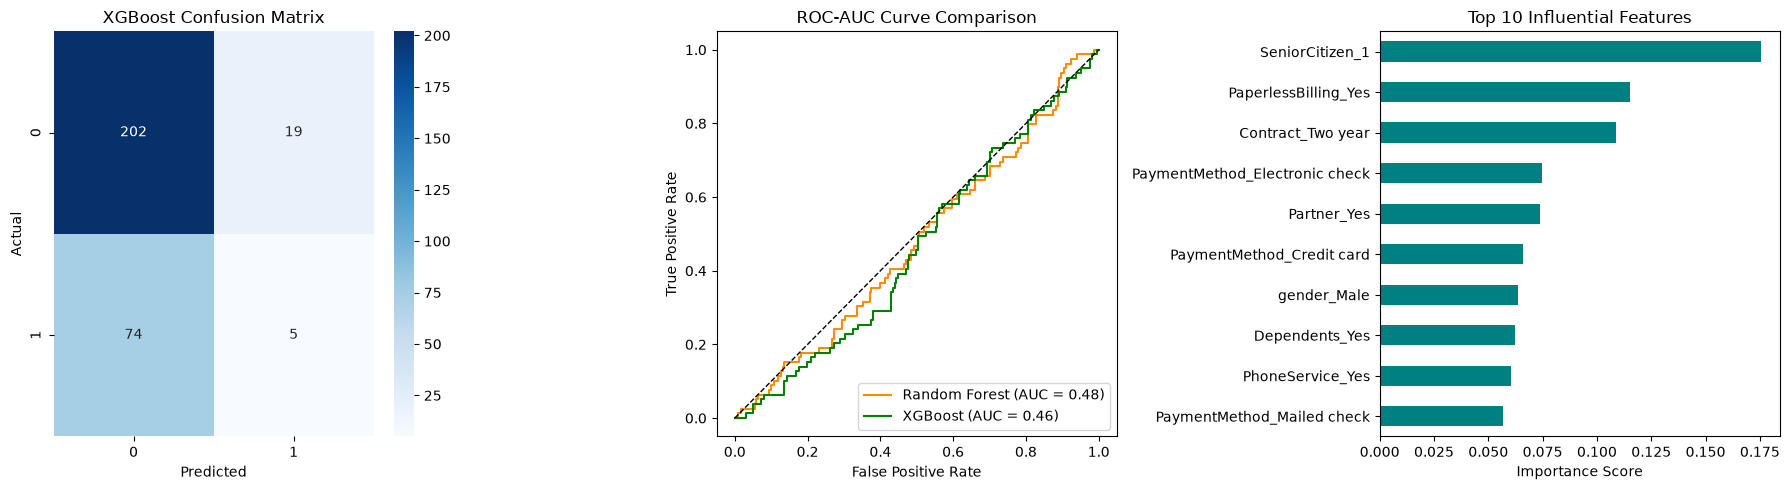

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix (XGBoost)
cm = confusion_matrix(y_test, xgb_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# 2. ROC-AUC Curves
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

axes[1].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.2f})', color='darkorange')
axes[1].plot(xgb_fpr, xgb_tpr, label=f'XGBoost (AUC = {roc_auc_score(y_test, xgb_probs):.2f})', color='green')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC-AUC Curve Comparison')
axes[1].legend(loc='lower right')

# 3. Top 10 Feature Importances (XGBoost)
importances = pd.Series(xgb_model.feature_importances_, index=all_feature_names).sort_values(ascending=False).head(10)
importances.plot(kind='barh', ax=axes[2], color='teal')
axes[2].invert_yaxis()
axes[2].set_title('Top 10 Influential Features')
axes[2].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()